# Notebook 3: RNN vs LSTM vs GRU
**Phase 3, Day 3**

In this notebook: (1) parameter counts, (2) a three-way comparison on a long-memory task, (3) a three-way comparison on sine forecasting, (4) a visualisation of the LSTM gates.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

torch.manual_seed(42)
np.random.seed(42)

## Part 1: One model class, three cell types
All three share the same interface, only the cell changes. Many-to-one: the output of the last time step goes into `nn.Linear`.

In [2]:
class SeqModel(nn.Module):
    def __init__(self, kind, input_size=1, hidden=32, num_layers=1, dropout=0.0):
        super().__init__()
        cell = {"RNN": nn.RNN, "LSTM": nn.LSTM, "GRU": nn.GRU}[kind]
        # dropout only applies between layers, so it needs num_layers > 1
        self.rnn = cell(input_size, hidden, num_layers=num_layers,
                        batch_first=True, dropout=dropout if num_layers > 1 else 0.0)
        self.fc = nn.Linear(hidden, 1)

    def forward(self, x):
        out, _ = self.rnn(x)            # for LSTM the second value is (h_n, c_n); for RNN/GRU just h_n
        return self.fc(out[:, -1, :])

def count_params(m):
    return sum(p.numel() for p in m.parameters())

## Part 2: Parameter counts
In PyTorch an RNN layer has `H*(I+H) + 2H` parameters. An LSTM has **4x** that (3 gates + candidate), a GRU has **3x** (2 gates + candidate).

In [3]:
H = 32
rows = []
for kind in ("RNN", "LSTM", "GRU"):
    m = SeqModel(kind, hidden=H)
    cell_params = count_params(m.rnn)
    rows.append((kind, cell_params, count_params(m)))

base = rows[0][1]
print(f"{'Model':6s} {'cell params':>12s} {'total params':>13s} {'cell vs RNN':>12s}")
for kind, c, tot in rows:
    print(f"{kind:6s} {c:12d} {tot:13d} {c/base:11.1f}x")

Model   cell params  total params  cell vs RNN
RNN            1120          1153         1.0x
LSTM           4480          4513         4.0x
GRU            3360          3393         3.0x


## Part 3: Long-memory task
**Task:** in a sequence of length 50 only the **first element** matters (positive or not), the other 49 are noise. Random guessing = 50% accuracy.

Note: the LSTM forget-gate bias is set to 1 (a common trick) so that the LSTM starts out leaning towards remembering.

In [4]:
def memory_task(T, n):
    x = torch.randn(n, T, 1)
    y = (x[:, 0, 0] > 0).float().unsqueeze(-1)
    return x, y

def train_memory(kind, T=50, steps=1500, lr=5e-3, seed=0):
    torch.manual_seed(seed)
    Xtr, ytr = memory_task(T, 4000)
    Xte, yte = memory_task(T, 1000)
    m = SeqModel(kind, hidden=32)
    if kind == "LSTM":
        H = 32
        with torch.no_grad():
            m.rnn.bias_ih_l0[H:2*H].fill_(1.0)   # PyTorch gate order: input, forget, cell, output
    opt = torch.optim.Adam(m.parameters(), lr=lr)
    lf = nn.BCEWithLogitsLoss()
    losses = []
    t0 = time.time()
    for s in range(steps):
        idx = torch.randint(0, len(Xtr), (64,))
        opt.zero_grad()
        loss = lf(m(Xtr[idx]), ytr[idx])
        loss.backward()
        nn.utils.clip_grad_norm_(m.parameters(), 1.0)
        opt.step()
        losses.append(loss.item())
    secs = time.time() - t0
    m.eval()
    with torch.no_grad():
        acc = ((m(Xte) > 0).float() == yte).float().mean().item()
    return m, losses, acc, secs

results, models = {}, {}
for kind in ("RNN", "LSTM", "GRU"):
    m, losses, acc, secs = train_memory(kind)
    models[kind] = m
    results[kind] = (losses, acc, secs)
    print(f"{kind:5s}  accuracy={acc:.2f}  time={secs:.1f}s  params={count_params(m)}")

RNN    accuracy=0.80  time=18.4s  params=1153
LSTM   accuracy=1.00  time=11.1s  params=4513
GRU    accuracy=0.53  time=50.2s  params=3393


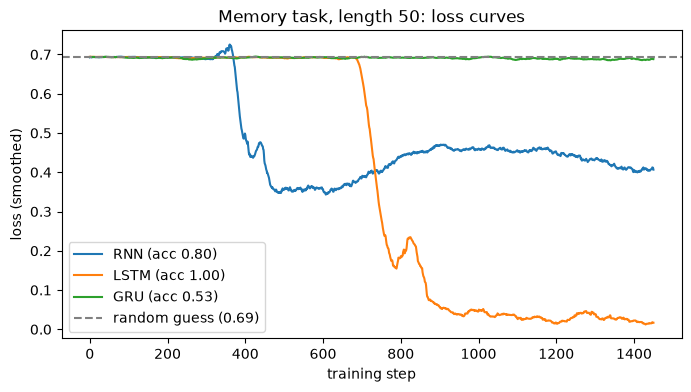

In [5]:
def smooth(x, k=50):
    return np.convolve(x, np.ones(k) / k, mode="valid")

plt.figure(figsize=(8, 4))
for kind, (losses, acc, secs) in results.items():
    plt.plot(smooth(losses), label=f"{kind} (acc {acc:.2f})")
plt.axhline(np.log(2), color="gray", ls="--", label="random guess (0.69)")
plt.xlabel("training step"); plt.ylabel("loss (smoothed)")
plt.title("Memory task, length 50: loss curves")
plt.legend(); plt.show()

**Observation (write in your own words):** which model learned the task and which did not, and why? Results can differ a little between runs (try changing the seed).

## Part 4: Three-way comparison on sine forecasting

In [6]:
n = 1000
t = np.arange(n)
series = np.sin(2 * np.pi * t / 50) + 0.1 * np.random.randn(n)

n_train, n_val = int(0.70 * n), int(0.15 * n)
train_raw = series[:n_train]
val_raw   = series[n_train:n_train + n_val]
test_raw  = series[n_train + n_val:]
mean, std = train_raw.mean(), train_raw.std()
train, val, test = [(a - mean) / std for a in (train_raw, val_raw, test_raw)]

def to_tensors(d, k=20):
    X = np.array([d[i:i + k] for i in range(len(d) - k)])
    y = np.array([d[i + k] for i in range(len(d) - k)])
    return (torch.tensor(X, dtype=torch.float32).unsqueeze(-1),
            torch.tensor(y, dtype=torch.float32).unsqueeze(-1))

X_train, y_train = to_tensors(train)
X_val,   y_val   = to_tensors(val)
X_test,  y_test  = to_tensors(test)

def train_forecast(kind, epochs=30, bs=32, lr=1e-3):
    torch.manual_seed(0)
    m = SeqModel(kind, hidden=32)
    opt = torch.optim.Adam(m.parameters(), lr=lr)
    lf = nn.MSELoss()
    tr_l, va_l = [], []
    t0 = time.time()
    for ep in range(epochs):
        m.train()
        perm = torch.randperm(len(X_train))
        tot = 0.0
        for i in range(0, len(perm), bs):
            idx = perm[i:i + bs]
            opt.zero_grad()
            loss = lf(m(X_train[idx]), y_train[idx])
            loss.backward()
            nn.utils.clip_grad_norm_(m.parameters(), 1.0)
            opt.step()
            tot += loss.item() * len(idx)
        tr_l.append(tot / len(X_train))
        m.eval()
        with torch.no_grad():
            va_l.append(lf(m(X_val), y_val).item())
    return m, tr_l, va_l, time.time() - t0

mae  = lambda a, b: np.mean(np.abs(a - b))
rmse = lambda a, b: np.sqrt(np.mean((a - b) ** 2))
real  = y_test.squeeze().numpy()
naive = X_test[:, -1, 0].numpy()

fc_models, fc_curves, fc_preds = {}, {}, {}
print(f"{'Model':6s} {'MAE':>7s} {'RMSE':>7s} {'time(s)':>8s}")
print(f"{'Naive':6s} {mae(real, naive):7.4f} {rmse(real, naive):7.4f} {'-':>8s}")
for kind in ("RNN", "LSTM", "GRU"):
    m, tr_l, va_l, secs = train_forecast(kind)
    m.eval()
    with torch.no_grad():
        p = m(X_test).squeeze().numpy()
    fc_models[kind], fc_curves[kind], fc_preds[kind] = m, (tr_l, va_l), p
    print(f"{kind:6s} {mae(real, p):7.4f} {rmse(real, p):7.4f} {secs:8.1f}")

Model      MAE    RMSE  time(s)
Naive   0.1762  0.2247        -
RNN     0.1138  0.1441      7.9
LSTM    0.1150  0.1440      5.7
GRU     0.1153  0.1452     17.3


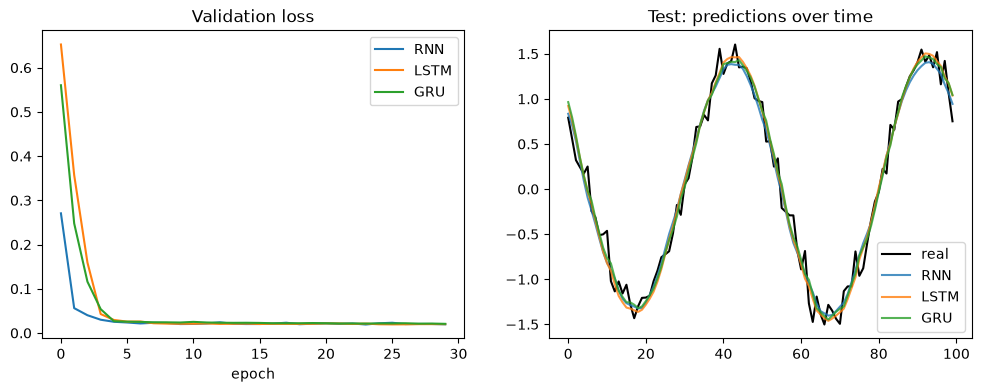

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for kind, (tr_l, va_l) in fc_curves.items():
    ax[0].plot(va_l, label=kind)
ax[0].set_title("Validation loss"); ax[0].set_xlabel("epoch"); ax[0].legend()

ax[1].plot(real[:100], label="real", color="black")
for kind, p in fc_preds.items():
    ax[1].plot(p[:100], label=kind, alpha=0.8)
ax[1].set_title("Test: predictions over time"); ax[1].legend()
plt.show()

**Observation:** on an easy task like a sine wave all three perform about the same. The difference shows up when long memory is needed (Part 3).

## Part 5: Visualising the LSTM gates
Using the weights of the trained LSTM from Part 3 we compute the gates **by hand** (PyTorch order: input, forget, cell, output) and see how they change over time for one sequence.

In [8]:
lstm_model = models["LSTM"]
lstm = lstm_model.rnn
H = 32

torch.manual_seed(1)
x_seq, _ = memory_task(50, 1)          # (1, 50, 1)
x_seq = x_seq[0]                        # (50, 1)

W_ih, W_hh = lstm.weight_ih_l0, lstm.weight_hh_l0
b = lstm.bias_ih_l0 + lstm.bias_hh_l0

h = torch.zeros(H); c = torch.zeros(H)
gates = {"input": [], "forget": [], "output": []}
cell_states = []
with torch.no_grad():
    for step in range(len(x_seq)):
        z = W_ih @ x_seq[step] + W_hh @ h + b
        i, f, g, o = z.chunk(4)
        i, f, g, o = torch.sigmoid(i), torch.sigmoid(f), torch.tanh(g), torch.sigmoid(o)
        c = f * c + i * g               # cell state is updated by addition
        h = o * torch.tanh(c)
        gates["input"].append(i.numpy()); gates["forget"].append(f.numpy())
        gates["output"].append(o.numpy()); cell_states.append(c.numpy())

# Check: does the manual result match nn.LSTM?
with torch.no_grad():
    out, _ = lstm(x_seq.unsqueeze(0))
print("Manual LSTM == nn.LSTM ?", torch.allclose(h, out[0, -1], atol=1e-5))
print("First element:", round(x_seq[0, 0].item(), 2), "(positive)" if x_seq[0, 0] > 0 else "(negative)")

Manual LSTM == nn.LSTM ? True
First element: -1.53 (negative)


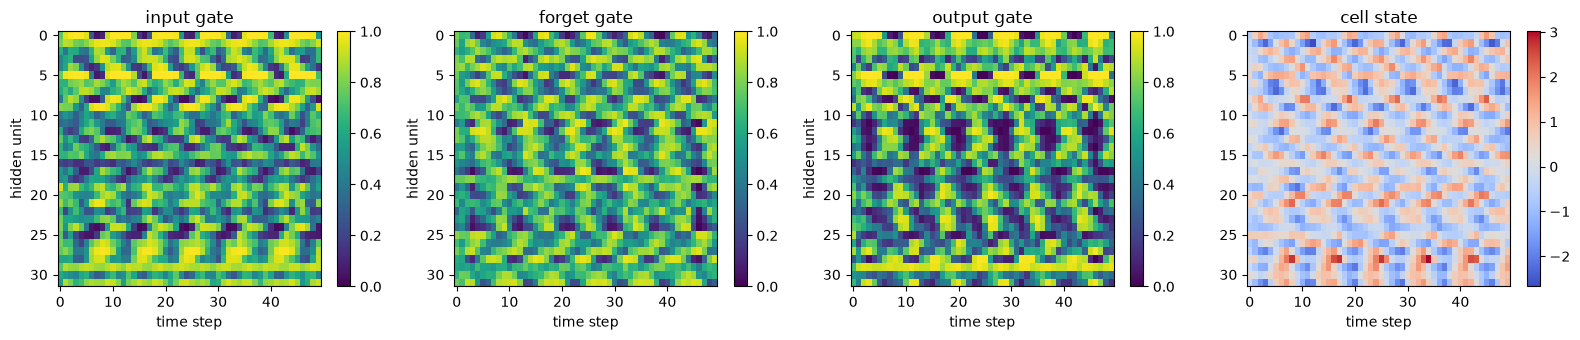

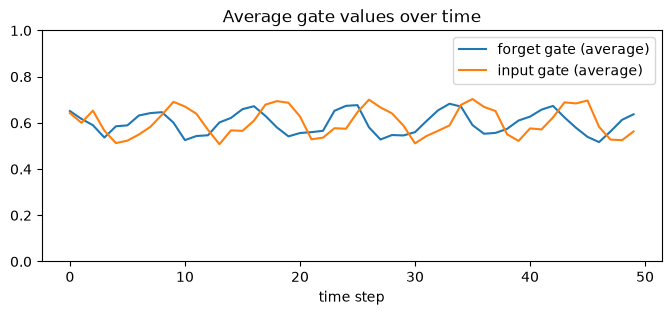

In [9]:
fig, ax = plt.subplots(1, 4, figsize=(16, 3.5))
for a, (name, arr) in zip(ax[:3], gates.items()):
    im = a.imshow(np.array(arr).T, aspect="auto", cmap="viridis", vmin=0, vmax=1)
    a.set_title(f"{name} gate"); a.set_xlabel("time step"); a.set_ylabel("hidden unit")
    plt.colorbar(im, ax=a)
im = ax[3].imshow(np.array(cell_states).T, aspect="auto", cmap="coolwarm")
ax[3].set_title("cell state"); ax[3].set_xlabel("time step")
plt.colorbar(im, ax=ax[3])
plt.tight_layout(); plt.show()

plt.figure(figsize=(8, 3))
plt.plot(np.mean(gates["forget"], axis=1), label="forget gate (average)")
plt.plot(np.mean(gates["input"], axis=1), label="input gate (average)")
plt.xlabel("time step"); plt.ylim(0, 1); plt.legend()
plt.title("Average gate values over time"); plt.show()

**Observation:** a forget gate close to 1 keeps old memory, close to 0 erases it. The input gate controls how much new input is written. Check: is the input gate open at the first step, and does the forget gate stay near 1 afterwards?

## Summary (write in your own words)
- The job of the 3 LSTM gates and the cell state:
- How a GRU differs from an LSTM:
- Parameter counts (RNN : GRU : LSTM = 1 : 3 : 4):
- Who wins on the memory task and why: